# 11 - Dead-ball evidence and hierarchical decoding

## 1. Controlled experiment design

We compare a 2x2 matrix: legacy/signed evidence versus joint/hierarchical decoding. A separate carry ablation extends confirmed-outside evidence through a bounded immediately following ball gap. No A1/A2 acquisition, D1 or hard 2-second duration filter is combined here. No public GT, scoreboard tuning or manual labels.

| Case | Evidence | Decoder | Carry |
|---|---|---|---|
| F1_replay | Original F1 | Joint | No |
| D2_joint | Signed D2 | Joint | No |
| Legacy_hier | Original F1 | LD then HA | No |
| D2_hier | Signed D2 | LD then HA | No |
| D3_carry | Signed D2 | LD then HA | Bounded |

Replay reuses verified features/events/slots from canonical F1. Every model recomputes quality, evidence, decoding, boundary and submission; no original predictions are used as model input. Player arrays are not loaded (video/player association audit disabled). Original runs are immutable. Default Run All will read pinned completed IDs after the example runs finish.

In [1]:
from pathlib import Path
from copy import deepcopy
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'games.py').is_file())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.artifacts import list_runs,read_json,read_table
from src.pipeline import run_pipeline
pd.set_option('display.max_columns',None)
REFERENCE_RUN_ID='20261115_232213_442294_bf05582d'
reference_dir=next(Path(r['path']) for r in list_runs(project_dir=ROOT) if r['run_id']==REFERENCE_RUN_ID)
reference_manifest=read_json(reference_dir)
STORAGE_CONFIG=ROOT/'config/artifacts_d2.yaml'
CONFIG_PATHS={'F1_replay':ROOT/'config/f1.yaml','D2_joint':ROOT/'config/d2.yaml',
    'Legacy_hier':ROOT/'config/ld_hierarchical.yaml','D2_hier':ROOT/'config/d2_hierarchical.yaml','D3_carry':ROOT/'config/d3_carry.yaml'}
configs={name:yaml.safe_load(p.read_text(encoding='utf-8-sig')) for name,p in CONFIG_PATHS.items()}
assert configs['F1_replay']==read_json(reference_dir,'config/model.json')
check=deepcopy(configs['D2_joint']);assert check['live_dead'].pop('model')=='signed';signed_settings=check['live_dead'].pop('signed');assert check==configs['F1_replay']
check=deepcopy(configs['Legacy_hier']);assert check['temporal'].pop('method')=='hierarchical';assert check==configs['F1_replay']
check=deepcopy(configs['D2_hier']);assert check['temporal'].pop('method')=='hierarchical';assert check==configs['D2_joint']
check=deepcopy(configs['D3_carry']);assert check['live_dead']['signed'].pop('carry_enabled');other=deepcopy(configs['D2_hier']);other['live_dead']['signed'].pop('carry_enabled');assert check==other
print('Feature reference:',REFERENCE_RUN_ID)
display(signed_settings)
display(yaml.safe_load(STORAGE_CONFIG.read_text(encoding='utf-8-sig')))

Feature reference: 20261115_232213_442294_bf05582d


{'prior_delta': -0.3, 'player_window_frames': 50, 'ball_lag_frames': 5, 'ball_window_frames': 25, 'minimum_window_fraction': 0.6, 'minimum_player_quality': 0.65, 'walking_speed_mps': 1.3, 'pace_scale_mps': 0.5, 'pace_weight': 0.3, 'still_speed_mps': 0.5, 'still_weight': 0.35, 'fast_speed_mps': 5.0, 'fast_weight': 0.4, 'outside_margin_m': 0.5, 'outside_confirm_frames': 3, 'outside_weight': 1.2, 'anchor_weight': 0.3, 'carry_enabled': False, 'carry_max_frames': 75}

{'root_dir': 'artifacts', 'submission_filename': 'baseline_d2.csv'}

## 2. Evidence semantics and initial scale

D2 delta = Dead minus Live. It is an engineered utility, not calibrated log odds or confidence. Live=-delta/2 and Dead=delta/2 is only a representation; the new observations/contributions are the intervention.

| Term | Initial value | Meaning |
|---|---|---|
| prior | -0.30 | Same prior gap as old 0.25-0.55 |
| collective pace | 0.30 * clip((1.3-motion)/0.5, -2,2) | Slow players support D; fast players support Live; robust per-team inputs, 50-frame mean |
| stationary ball | +0.35 | Qualified current lag/25-frame speed <0.5, inside pitch; no mandatory tag |
| fast ball | -0.40 | Qualified inside ball speed >5, can offset maximum slow pace + prior |
| confirmed outside | +1.20 | >0.5 m beyond any line, 3 consecutive reliable observations |
| stoppage anchor | +0.30 * existing pulse | Weak automatic SET PIECES start context; not whole-tag D |
| carry (separate case) | decaying outside contribution | Immediately following missing frames only, max75 frames; any visible nonconfirmed observation resets |

Motion smoothing is centred/offline, half/frame-block local, >=60% valid window, with a valid current measurement. Missing ball/player motion does not become stationary. No long-missing bonus. Quiet live with identical cues to stoppage remains unidentifiable; weights are frozen hypotheses, not selected from possession count or public GT.

Hierarchy retains existing HD/DH/HA cost scales and hints. LD ignores relative team preference; HA resets per live interval. D boundaries are immutable during HA boundary refinement. No hard minimum D/Live duration is added.
The original joint decoder retains its existing weak short-run prior; hierarchical decoding applies that prior only to HA inside Live. LD has no post-duration filter. `short_runs_merged` is zero in all five completed cases, so that prior did not explicitly merge any run here.


In [2]:
RUN_EXPERIMENTS = False
EXPERIMENT_RUN_IDS = {'F1_replay': '20261116_152441_833333_b01d4093', 'D2_joint': '20261116_152505_663609_24930f93', 'Legacy_hier': '20261116_152530_709280_e9cb59ff', 'D2_hier': '20261116_152556_094636_fc00d6d7', 'D3_carry': '20261116_152622_757152_f4f7fe24'}
folders={};manifests={}
for name,cfg in configs.items():
    if name in EXPERIMENT_RUN_IDS:
        folder=next(Path(r['path']) for r in list_runs(project_dir=ROOT) if r['run_id']==EXPERIMENT_RUN_IDS[name])
    elif RUN_EXPERIMENTS:
        result=run_pipeline(cfg,project_dir=ROOT,storage_config_path=STORAGE_CONFIG,
            output_path=f'baseline_{name.lower()}.csv',feature_run_dir=reference_dir,
            execution_metadata={'experiment':'D2_game_state_ablation','case':name,'parent_run_id':REFERENCE_RUN_ID,
                'notebook':'notebooks/11_dead_ball_redesign.ipynb','model_config_source':str(CONFIG_PATHS[name])})
        folder=Path(result.artifact_dir);EXPERIMENT_RUN_IDS[name]=result.run_id
        display({'experiment':name,'run_id':result.run_id})
    else:raise RuntimeError(f'No completed run ID for {name}; enable RUN_EXPERIMENTS or supply an ID')
    m=read_json(folder)
    assert m['status']=='completed' and read_json(folder,'config/model.json')==cfg
    assert read_json(folder,'inputs/feature_replay.json')['run_id']==REFERENCE_RUN_ID
    folders[name]=folder;manifests[name]=m
    display({'case':name,'run_id':m['run_id'],'validator':read_json(folder,'submission/validator/result.json')['status']})
print('Every case owns config snapshots, verified inputs, intermediate outputs and submission.')

Every case owns config snapshots, verified inputs, intermediate outputs and submission.


{'case': 'F1_replay', 'run_id': '20261116_152441_833333_b01d4093', 'validator': 'passed'}

{'case': 'D2_joint', 'run_id': '20261116_152505_663609_24930f93', 'validator': 'passed'}

{'case': 'Legacy_hier', 'run_id': '20261116_152530_709280_e9cb59ff', 'validator': 'passed'}

{'case': 'D2_hier', 'run_id': '20261116_152556_094636_fc00d6d7', 'validator': 'passed'}

{'case': 'D3_carry', 'run_id': '20261116_152622_757152_f4f7fe24', 'validator': 'passed'}

## 3. Compatibility and intervention isolation

F1 replay must reproduce original scores, hints and labels exactly. All cases must preserve feature/quality/control/event values. For architecture-only comparisons, fusion utilities must be identical. Carry changes only the explicit carry flag and channel. Hierarchical final D mask must match decoded D, preventing refinement from undoing segmentation.

In [3]:
same_paths=['features/initial/frames.csv','features/initial/events.csv','features/initial/slots.csv']
for stage,file in [('quality','frames.csv'),('events','frames.csv'),('control','scores.csv'),('fusion','transition_hint.csv')]:
    same_paths.append(f'core/initial/{stage}/{file}')
checks=[]
for name,folder in folders.items():
    for path in same_paths:
        pd.testing.assert_frame_equal(read_table(reference_dir,path),read_table(folder,path),check_exact=True)
    checks.append({'case':name,'unchanged_features_quality_events_control_hint':True})
for path in ['core/initial/live_dead/frames.csv','core/initial/fusion/state_log_scores.csv','core/initial/decode/labels.csv','result/labels.csv']:
    pd.testing.assert_frame_equal(read_table(reference_dir,path),read_table(folders['F1_replay'],path),check_exact=True)
for left,right in [('F1_replay','Legacy_hier'),('D2_joint','D2_hier')]:
    pd.testing.assert_frame_equal(read_table(folders[left],'core/initial/fusion/state_log_scores.csv'),read_table(folders[right],'core/initial/fusion/state_log_scores.csv'),check_exact=True)
for name in ['Legacy_hier','D2_hier','D3_carry']:
    state=read_table(folders[name],'core/initial/decode/game_state.csv')
    final=read_table(folders[name],'result/labels.csv')
    np.testing.assert_array_equal(state.frame,final.frame)
    np.testing.assert_array_equal(state.dead_decoded,final.label.eq('D'))
    assert read_json(folders[name],'diagnostics/game_state/summary.json')['D_mask_refinement_changed_frames']==0
display(pd.DataFrame(checks))
print('PASS: exact F1 compatibility; isolated evidence/architecture/carry comparisons; fixed hierarchical D mask.')

PASS: exact F1 compatibility; isolated evidence/architecture/carry comparisons; fixed hierarchical D mask.


,case,unchanged_features_quality_events_control_hint
0,F1_replay,True
1,D2_joint,True
2,Legacy_hier,True
3,D2_hier,True
4,D3_carry,True


## 4. Score components and data availability

Read core/initial/live_dead/components.csv and metadata.json. Signed additive columns reconstruct Dead-minus-Live; negative fast_live supports Live. Lagged/smoothed speeds are measurements (m/s), valid-window fractions are coverage, not probabilities. Outside carry age=-1 means no active carry; support may decay before the label exits because it is not a forced hold.

Sources for behavior: diagnostics/game_state/{frames,natural_stoppages,boundary_context,availability_summary}.csv and summary.json. Natural excludes the published forced second-half D. Unlike our prior game-state audit, no model GT is used.

In [4]:
for name in ['D2_joint','D2_hier','D3_carry']:
    folder=folders[name];c=read_table(folder,'core/initial/live_dead/components.csv');meta=read_json(folder,'core/initial/live_dead/metadata.json')
    raw=read_table(folder,'core/initial/live_dead/frames.csv')
    np.testing.assert_array_equal(c.frame,raw.frame)
    np.testing.assert_allclose(c[meta['signed_additive_columns']].sum(axis=1),raw.dead_score-raw.live_score,rtol=0,atol=1e-12)
    if name!='D3_carry':assert c.carry_dead.eq(0).all()
    display({'case':name,'model':meta['model'],'carry_enabled':meta['settings']['carry_enabled']})
display(read_json(folders['D2_joint'],'core/initial/live_dead/metadata.json'))
display(read_table(folders['D2_joint'],'diagnostics/game_state/availability_summary.csv'))

{'case': 'D2_joint', 'model': 'signed', 'carry_enabled': False}

{'case': 'D2_hier', 'model': 'signed', 'carry_enabled': False}

{'case': 'D3_carry', 'model': 'signed', 'carry_enabled': True}

{'model': 'signed', 'settings': {'prior_delta': -0.3, 'player_window_frames': 50, 'ball_lag_frames': 5, 'ball_window_frames': 25, 'minimum_window_fraction': 0.6, 'minimum_player_quality': 0.65, 'walking_speed_mps': 1.3, 'pace_scale_mps': 0.5, 'pace_weight': 0.3, 'still_speed_mps': 0.5, 'still_weight': 0.35, 'fast_speed_mps': 5.0, 'fast_weight': 0.4, 'outside_margin_m': 0.5, 'outside_confirm_frames': 3, 'outside_weight': 1.2, 'anchor_weight': 0.3, 'carry_enabled': False, 'carry_max_frames': 75}, 'fps': 25.0, 'pitch_m': [105.3, 68.0], 'signed_additive_columns': ['prior_delta', 'pace_dead', 'still_dead', 'fast_live', 'outside_dead', 'carry_dead', 'anchor_dead'], 'semantics': 'engineered uncalibrated signed Dead-minus-Live utility; live=-delta/2, dead=delta/2; not probabilities', 'smoothing': 'centred offline fixed-denominator coverage windows, reset at half/frame gap; current valid measurement required; no missing-to-stationary substitution', 'carry': 'only confirmed observed outside -> i

,half,ball_observed,ball_motion_reliable,motion_evidence_available,frames,dead_frames,mean_dead_advantage
0,1,False,False,False,6336,0,-0.300000
1,1,False,False,True,25968,7597,-0.191304
2,1,True,False,False,2,0,-0.300000
3,1,True,False,True,85,15,-0.265510
4,1,True,True,False,285,182,0.472281
5,1,True,True,True,46791,3185,-0.724000
6,2,False,False,False,2574,0,-0.297086
7,2,False,False,True,29201,10798,-0.131754
8,2,True,False,False,1,1,-0.300000
9,2,True,False,True,107,38,-0.146184


## 5. Behavioral comparison, not model ranking

Raw D wins indicate local evidence coverage. Natural D labels/intervals describe temporal behavior. HA short spells may increase when D correctly or incorrectly splits a possession; neither more D nor fewer short spells proves accuracy. The matrix isolates evidence effects within a decoder and decoder effects within an evidence model. Do not select a case from public scores or plausible-looking counts.

In [5]:
rows=[]
for name,folder in folders.items():
    diag=read_json(folder,'submission/diagnostics.json');gs=read_json(folder,'diagnostics/game_state/summary.json')
    seg=read_table(folder,'diagnostics/final/prediction/segment_summary.csv')
    ha=seg.loc[seg.label.isin(['H','A'])]
    rows.append({'case':name,'positive_D_frames':gs['positive_dead_preference_frames'],'natural_D_frames':gs['natural_D_frames'],
        'natural_D_intervals':gs['natural_D_intervals'],'median_D_s':gs['median_D_duration_s'],
        'HA_spells':diag['possession_spells'],'short_HA_lt2s':int(ha.segments_lt_2s.sum()),
        'median_HA_s':diag['possession_median_s'],'total_transitions':diag['total_transitions'],
        'D_mask_refinement_changes':gs['D_mask_refinement_changed_frames']})
comparison=pd.DataFrame(rows).set_index('case');display(comparison)
# These are intervention effects, not gains in correctness.

,positive_D_frames,natural_D_frames,natural_D_intervals,median_D_s,HA_spells,short_HA_lt2s,median_HA_s,total_transitions,D_mask_refinement_changes
case,,,,,,,,,
F1_replay,169,63,1,2.52,1070,523,2.04,1070,1
D2_joint,26110,25533,136,3.66,1138,558,2.04,1273,13
Legacy_hier,169,36,1,1.44,1071,524,2.04,1071,0
D2_hier,26110,24869,127,3.88,1148,564,2.04,1274,0
D3_carry,26807,25558,128,3.96,1148,564,2.04,1275,0


## 6. Interval context and restart behavior

Inspect all natural stoppages without labelling them manually. Data availability inside predicted D can distinguish observed/unknown regimes, but missing is not GT D. LD boundary tables record direction, evidence and observation status. Compare pre-refinement and final boundaries, especially for joint models; hierarchical D boundaries are fixed.

Smoothing can shift boundaries and the +/-6-frame refinement cannot correct an arbitrary one-second lag. A tag start/end is context, not a verified stoppage/restart. No snapping to manual frame annotations.

In [6]:
for name in ['D2_joint','D2_hier','D3_carry']:
    print(name)
    stops=read_table(folders[name],'diagnostics/game_state/natural_stoppages.csv')
    display(stops.head(20))
    boundaries=read_table(folders[name],'diagnostics/game_state/boundary_context.csv')
    display(boundaries.groupby(['stage','from','to']).agg(boundaries=('frame','size'),observed_fraction=('ball_observed','mean'),
        mean_dead_advantage=('dead_advantage','mean')))
    if len(stops):display(stops[['duration_s','observed_fraction','mean_dead_advantage']].describe())

D2_joint
D2_hier
D3_carry


,half,start_frame,end_frame,n_frames,duration_s,observed_fraction,mean_dead_advantage
0,1,17317,17324,8,0.32,1.000000,-0.057985
1,1,18028,18122,95,3.80,1.000000,0.317199
2,1,19519,19664,146,5.84,0.000000,0.025683
3,1,20118,20127,10,0.40,1.000000,0.732132
4,1,20872,20944,73,2.92,1.000000,0.038402
5,1,21614,21689,76,3.04,1.000000,0.783829
6,1,25377,25547,171,6.84,1.000000,1.101118
7,1,27087,27125,39,1.56,1.000000,0.208961
8,1,27771,27925,155,6.20,0.793548,0.700671
9,1,29541,29633,93,3.72,0.000000,0.098056


boundaries  observed_fraction  mean_dead_advantage
stage   from to                                                    
decoded A    D           63           0.587302             0.267273
        D    A           71           0.647887            -0.242632
             H           66           0.575758            -0.266730
        H    D           73           0.506849             0.272502
final   A    D           63           0.587302             0.266572
        D    A           71           0.647887            -0.242632
             H           66           0.575758            -0.266730
        H    D           73           0.506849             0.270711

,duration_s,observed_fraction,mean_dead_advantage
count,136.000000,136.000000,136.000000
mean,7.509706,0.567737,0.377858
std,10.297909,0.474144,0.352050
min,0.160000,0.000000,-0.057985
25%,1.440000,0.000000,0.108280
50%,3.660000,0.994083,0.215951
75%,8.110000,1.000000,0.732378
max,59.680000,1.000000,1.155597


,half,start_frame,end_frame,n_frames,duration_s,observed_fraction,mean_dead_advantage
0,1,18028,18122,95,3.80,1.000000,0.317199
1,1,19520,19664,145,5.80,0.000000,0.025702
2,1,20120,20127,8,0.32,1.000000,0.971865
3,1,21614,21689,76,3.04,1.000000,0.783829
4,1,25377,25547,171,6.84,1.000000,1.101118
5,1,27087,27125,39,1.56,1.000000,0.208961
6,1,27772,27905,134,5.36,0.768657,0.819176
7,1,29541,29633,93,3.72,0.000000,0.098056
8,1,29693,29765,73,2.92,0.000000,0.094074
9,1,31962,31985,24,0.96,1.000000,0.251649


boundaries  observed_fraction  mean_dead_advantage
stage   from to                                                    
decoded A    D           63           0.587302             0.324485
        D    A           68           0.632353            -0.222645
             H           60           0.600000            -0.261717
        H    D           64           0.484375             0.351545
final   A    D           63           0.587302             0.324485
        D    A           68           0.632353            -0.222645
             H           60           0.600000            -0.261717
        H    D           64           0.484375             0.351545

,duration_s,observed_fraction,mean_dead_advantage
count,127.000000,127.000000,127.000000
mean,7.832756,0.561404,0.412365
std,10.457602,0.476034,0.366500
min,0.160000,0.000000,0.025702
25%,1.560000,0.000000,0.127168
50%,3.880000,0.994048,0.225038
75%,8.460000,1.000000,0.817118
max,59.680000,1.000000,1.155597


,half,start_frame,end_frame,n_frames,duration_s,observed_fraction,mean_dead_advantage
0,1,18028,18122,95,3.80,1.000000,0.317199
1,1,19520,19664,145,5.80,0.000000,0.025702
2,1,20120,20127,8,0.32,1.000000,0.971865
3,1,21614,21689,76,3.04,1.000000,0.783829
4,1,25377,25547,171,6.84,1.000000,1.101118
5,1,27087,27125,39,1.56,1.000000,0.208961
6,1,27772,27905,134,5.36,0.768657,0.819176
7,1,29541,29633,93,3.72,0.000000,0.098056
8,1,29693,29765,73,2.92,0.000000,0.094074
9,1,31962,31985,24,0.96,1.000000,0.251649


boundaries  observed_fraction  mean_dead_advantage
stage   from to                                                    
decoded A    D           62           0.596774             0.329262
        D    A           68           0.632353            -0.203857
             H           61           0.590164            -0.227547
        H    D           66           0.500000             0.358941
final   A    D           62           0.596774             0.329262
        D    A           68           0.632353            -0.203857
             H           61           0.590164            -0.227547
        H    D           66           0.500000             0.358941

,duration_s,observed_fraction,mean_dead_advantage
count,128.000000,128.000000,128.000000
mean,7.986875,0.500859,0.390360
std,10.348364,0.466020,0.344114
min,0.160000,0.000000,0.025702
25%,2.200000,0.000000,0.127569
50%,3.960000,0.312905,0.225319
75%,8.980000,1.000000,0.684757
max,59.680000,1.000000,1.155597


## 7. Confirmed-outside carry ablation

Compare D2_hier versus D3_carry: all channels except carry_dead must remain identical. Carry is activated only by confirmed reliable outside observations followed by missing ball, bounded to 75 frames, with decay and reset. Its expiry is not an instruction to force Live, and active carry is not an instruction to force D. Both labels still follow temporal inference.

In [7]:
base=read_table(folders['D2_hier'],'core/initial/live_dead/components.csv')
held=read_table(folders['D3_carry'],'core/initial/live_dead/components.csv')
np.testing.assert_array_equal(base.frame,held.frame)
for column in ['prior_delta','pace_dead','still_dead','fast_live','outside_dead','anchor_dead','smoothed_player_motion','smoothed_ball_speed_mps']:
    np.testing.assert_array_equal(base[column],held[column])
assert base.carry_dead.eq(0).all()
np.testing.assert_allclose(held.dead_minus_live-base.dead_minus_live,held.carry_dead,rtol=0,atol=1e-12)
assert held.outside_carry_age_frames.le(configs['D3_carry']['live_dead']['signed']['carry_max_frames']).all()
print('PASS: carry is the only changed evidence contribution.')
display(held.loc[held.outside_carry_support.gt(0),['outside_carry_age_frames','outside_carry_support','carry_dead']].describe())

PASS: carry is the only changed evidence contribution.


,outside_carry_age_frames,outside_carry_support,carry_dead
count,1052.000000,1052.000000,1052.000000
mean,37.930608,0.500913,0.601096
std,21.696811,0.285484,0.342581
min,1.000000,0.013158,0.015789
25%,19.000000,0.250000,0.300000
50%,38.000000,0.500000,0.600000
75%,57.000000,0.750000,0.900000
max,75.000000,0.986842,1.184211


## 8. Automatically selected evidence example

Choose the strongest carry contribution, if available, otherwise strongest natural D2 advantage. Plot components and predictions in a +/-3 s same-half window. This is an algorithmic example, not proof of correct labels. All plotted scores come from pipeline artifacts.

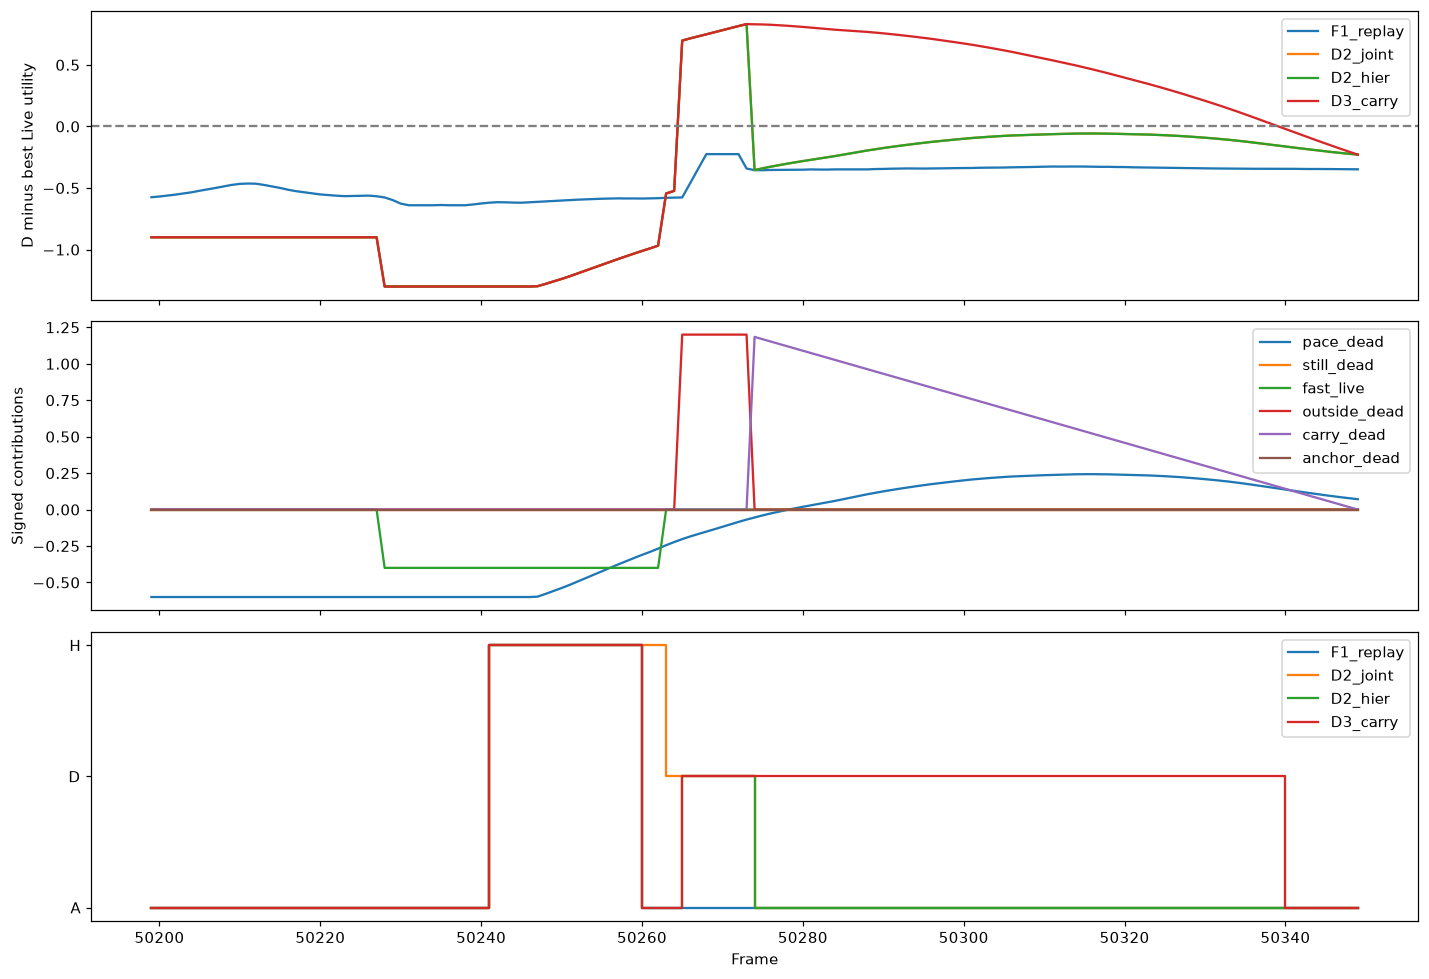

In [8]:
view=read_table(folders['D3_carry'],'diagnostics/game_state/frames.csv')
if (held.carry_dead.gt(0)&view.natural).any():
    ix=held.loc[held.carry_dead.gt(0)&view.natural,'carry_dead'].idxmax()
else:ix=view.loc[view.natural,'dead_minus_best_live'].idxmax()
center=int(view.loc[ix,'frame']);half=int(view.loc[ix,'half'])
window=view.loc[view.half.eq(half)&view.frame.between(center-75,center+75)&view.natural]
fig,axes=plt.subplots(3,1,figsize=(13,9),sharex=True)
for name in ['F1_replay','D2_joint','D2_hier','D3_carry']:
    table=read_table(folders[name],'diagnostics/game_state/frames.csv')
    w=table.loc[table.half.eq(half)&table.frame.between(center-75,center+75)&table.natural]
    axes[0].plot(w.frame,w.dead_minus_best_live,label=name)
    axes[2].step(w.frame,w.final_label.map({'H':1,'D':0,'A':-1,'X':np.nan}),where='post',label=name)
axes[0].axhline(0,color='grey',linestyle='--');axes[0].set_ylabel('D minus best Live utility');axes[0].legend()
indices=window.index
held.loc[indices].plot(x='frame',y=['pace_dead','still_dead','fast_live','outside_dead','carry_dead','anchor_dead'],ax=axes[1])
axes[1].set_ylabel('Signed contributions');axes[2].set_yticks([-1,0,1],['A','D','H']);axes[2].legend();axes[2].set_xlabel('Frame')
for ax in axes:ax.ticklabel_format(axis='x',style='plain',useOffset=False)
plt.tight_layout();plt.show()

## 9. Synthetic checks and limitations

Source constructs placed stoppage, running Live, stationary ball with active players, fast inside ball with slow players, missing ball while players move, all motion unavailable, an isolated outside outlier, outside-then-missing, and restart. Each is scored through production fusion and both decoders. Live trajectories remain inside the pitch. The contracts check representative stable regions, not exact boundary accuracy.

Identical quiet-Live and stoppage observations cannot be guaranteed separable. Unknown is not slow/stationary. Carry does not originate from missing alone and cannot bridge halves/gaps. No hard minimum duration is used. These tests do not measure full-match accuracy/spellF1.

In [9]:
for name in ['D2_joint','D3_carry']:
    print(name)
    tests=read_table(folders[name],'diagnostics/game_state_synthetic/summary.csv')
    display(tests);assert tests.passed.all()
display(read_json(folders['D2_joint'],'diagnostics/game_state_synthetic/metadata.json'))

D2_joint
D3_carry


,scenario,passed,joint_passed,hierarchical_passed,joint_D_frames,hierarchical_D_frames,carry_frames
0,placed_stoppage,True,True,True,320,320,0
1,running_live,True,True,True,0,0,0
2,quiet_live,True,True,True,0,0,0
3,fast_ball_slow_players,True,True,True,0,0,0
4,missing_live,True,True,True,0,0,0
5,missing_all,True,True,True,0,0,0
6,outside_outlier,True,True,True,0,0,0
7,outside_missing,True,True,True,17,17,0
8,restart,True,True,True,142,142,0


,scenario,passed,joint_passed,hierarchical_passed,joint_D_frames,hierarchical_D_frames,carry_frames
0,placed_stoppage,True,True,True,320,320,0
1,running_live,True,True,True,0,0,0
2,quiet_live,True,True,True,0,0,0
3,fast_ball_slow_players,True,True,True,0,0,0
4,missing_live,True,True,True,0,0,0
5,missing_all,True,True,True,0,0,0
6,outside_outlier,True,True,True,0,0,0
7,outside_missing,True,True,True,35,35,75
8,restart,True,True,True,142,142,0


{'source': 'synthetic observations only; no provided-match labels or public GT', 'scope': 'behavioral contracts, not match accuracy; both decoders use the same existing transition costs', 'limitation': 'quiet live and stoppage with identical observed cues cannot be guaranteed separable; running quiet-live case has active player motion', 'carry': 'support can decay before label expiry; no forced label hold until timeout'}

## 10. Interpretation and decisions

| Observation | Meaning / next decision |
|---|---|
| D2 adds positive preference and natural D | Evidence mechanism has wider coverage; not verified stoppages |
| Hierarchy changes labels with identical emissions | Temporal coupling matters; inspect LD/HA boundaries, not a score-scale claim |
| Old evidence stays weak under hierarchy | Architecture alone does not invent stoppage evidence |
| Carry affects only missing after confirmed outside | Expected scope; audit expiry and visible re-entry before expanding |
| Carry creates long/unsupported D | Keep bounded policy and inspect evidence; do not hold until next tag |
| Quiet-Live becomes D in indistinguishable contexts | Proxy limitation; seek independent evidence/validation, not target D share |
| Short spells change after D splits | Joint segmentation effect; fewer/more spells alone is not correctness |
| Hierarchical D mask changes during refinement | Implementation failure; stop and fix |

Hard min-dead/min-live 2 s remains deferred. No GT-driven parameter/window selection or A1/A2/D1 mixing. No model is adopted just because its D share resembles football expectations. Independent permitted validation is needed for accuracy claims.

In [10]:
display(Markdown('**Experiment set complete.** All cases use the same verified input features. F1 replay must match original predictions, '
    'architecture-only cases share emissions, and carry-only comparison shares all other contributions. '
    'Read the behavioral table as intervention effects, not accuracy ranking.'))
print('Pinned IDs:',EXPERIMENT_RUN_IDS)

Pinned IDs: {'F1_replay': '20261116_152441_833333_b01d4093', 'D2_joint': '20261116_152505_663609_24930f93', 'Legacy_hier': '20261116_152530_709280_e9cb59ff', 'D2_hier': '20261116_152556_094636_fc00d6d7', 'D3_carry': '20261116_152622_757152_f4f7fe24'}


**Experiment set complete.** All cases use the same verified input features. F1 replay must match original predictions, architecture-only cases share emissions, and carry-only comparison shares all other contributions. Read the behavioral table as intervention effects, not accuracy ranking.

## 11. Hasil run dan arah keputusan

Kelima run selesai, seluruh validator format lolos, dan F1 replay menghasilkan skor serta label yang identik dengan F1 historis. Semua kasus menggunakan fitur pertandingan yang sama; komputasi evidence, decoder, boundary, dan submission dijalankan ulang oleh pipeline. Tidak ada evaluasi akurasi terhadap public GT.

| Kasus | Frame natural D | Interval natural D | Median durasi D (s) |
|---|---:|---:|---:|
| F1 replay | 63 | 1 | 2.52 |
| D2 joint | 25,533 | 136 | 3.66 |
| Legacy hierarchical | 36 | 1 | 1.44 |
| D2 hierarchical | 24,869 | 127 | 3.88 |
| D3 carry | 25,558 | 128 | 3.96 |

**Temuan utama:** perubahan evidence menjadi faktor terbesar dalam perluasan cakupan D. Frame dengan preferensi lokal D naik dari 169 pada F1 menjadi 26,110 pada D2. Hierarki saja mempertahankan 169 frame tersebut dan menghasilkan 36 frame final D. Jadi, pemisahan LD dan HA tidak menggantikan kebutuhan akan evidence stoppage yang lebih baik.

Dengan emission D2 yang sama, hierarchy menghasilkan lebih sedikit D dibanding joint (24,869 versus 25,533 frame). Coupling decoder bersama dapat mendukung maupun menekan D; kita tidak boleh berasumsi hierarki selalu menambah D atau otomatis lebih benar. Seluruh mask D hierarchical identik sebelum dan sesudah boundary refinement. Seluruh run mencatat nol explicit short-run merge.

Carry menambah 689 frame D dan satu interval terhadap D2 hierarchical. Semua komponen selain carry identik, sehingga efek ini berasal dari perpanjangan evidence outside yang terkonfirmasi saat bola langsung missing. Jumlah HA spell dan spell pendek pada kedua kasus sama. Ini menunjukkan dampak mekanismenya terbatas pada pasangan ini, bukan membuktikan bahwa setiap frame tambahan adalah stoppage yang benar.

**Keputusan pengembangan:** simpan D2 joint dan D2 hierarchical sebagai kandidat, serta D3 sebagai ablation terpisah. Jangan mempromosikan salah satunya hanya berdasarkan jumlah D. Diagnosa berikutnya menelaah konteks interval pada CSV yang sudah disimpan: jika D didukung outside/stationary dan pace andal, periksa onset/restart; jika terutama pace pelan atau anchor tanpa dukungan bola, cari bukti pembeda quiet-Live sebelum mengubah bobot. Jika carry bertahan setelah bola masuk kembali, itu kegagalan implementasi; jika hanya meluas saat missing tetapi salah secara visual, kebijakan carry perlu ditinjau. Penetapan peningkatan akurasi memerlukan validasi independen yang diizinkan; tidak memakai public GT untuk memilih parameter. Minimum durasi keras 2 detik tetap ditunda.

Artifacts tiap kasus tercantum pada section 2. Jalur utama: `config/model.json`, `config/storage.json`, `inputs/feature_replay.json`, `core/initial/live_dead/components.csv`, `core/initial/decode/`, `diagnostics/game_state/`, dan `result/labels.csv`. Default Run All membaca hasil yang dipatok, tanpa membuat run baru.
